In [5]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_cohere import ChatCohere
from dotenv import load_dotenv

In [6]:
load_dotenv()

True

In [7]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str

In [8]:
parent_llm = ChatCohere(model="command-a-03-2025")
subgraph_llm = ChatCohere(model="command-a-03-2025")

In [10]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [11]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [ ]:
def generate_answer(state: ParentState):
    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [13]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

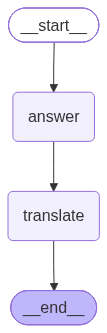

In [14]:
graph = parent_builder.compile()
graph

In [15]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': "Quantum physics, also known as quantum mechanics, is a branch of physics that deals with the behavior of matter and energy at the smallest scales, such as atoms and subatomic particles (e.g., electrons, photons, and quarks). It provides a fundamental description of the physical properties of nature at these scales, where classical physics (like Newtonian mechanics and electromagnetism) no longer applies.\n\nKey principles of quantum physics include:\n\n1. **Wave-Particle Duality**: Particles like electrons and photons exhibit both wave-like and particle-like properties. This duality is a cornerstone of quantum theory.\n\n2. **Quantization**: Certain physical properties, such as energy, come in discrete packets called quanta. For example, electrons in atoms can only occupy specific energy levels.\n\n3. **Superposition**: Quantum systems can exist in multiple states simultaneously until measured. This is often illustrated by Schrödi